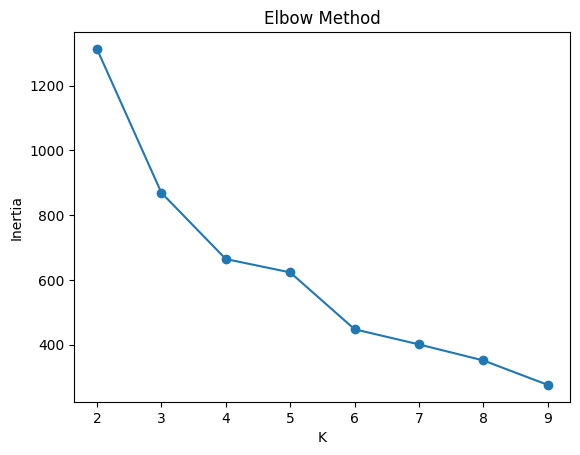

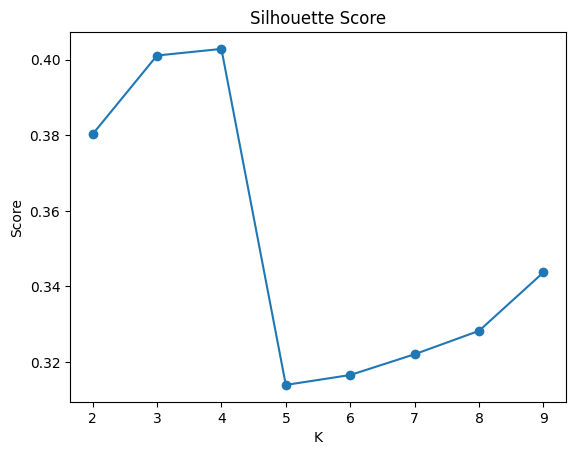

👉 K đề xuất: 4


In [5]:

# ===== IMPORT =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ===== LOAD DATA =====
df = pd.read_csv("DATASET_BAITOAN1.csv")

# ===== CHỌN FEATURE =====
features = ['mean_temp', 'min_temp', 'max_temp', 'std_temp', 'range_temp']
X = df[features].values

# ===== SCALE =====
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ===== KMEANS FROM SCRATCH =====
def kmeans(X, k, max_iter=100):
    np.random.seed(42)
    centroids = X[np.random.choice(len(X), k, replace=False)]

    for _ in range(max_iter):
        clusters = [[] for _ in range(k)]

        for x in X:
            distances = [np.linalg.norm(x - c) for c in centroids]
            idx = np.argmin(distances)
            clusters[idx].append(x)

        new_centroids = np.array([np.mean(cluster, axis=0) for cluster in clusters])

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return centroids, clusters

# ===== TÍNH ELBOW + SILHOUETTE =====
inertia_list = []
sil_scores = []
K_range = range(2, 10)

for k in K_range:
    centroids, clusters = kmeans(X_scaled, k)

    inertia = 0
    labels = np.zeros(len(X_scaled))

    for i, cluster in enumerate(clusters):
        for point in cluster:
            inertia += np.linalg.norm(point - centroids[i])**2
            idx = np.where((X_scaled == point).all(axis=1))[0][0]
            labels[idx] = i

    inertia_list.append(inertia)
    sil_scores.append(silhouette_score(X_scaled, labels))

# ===== VẼ =====
plt.figure()
plt.plot(K_range, inertia_list, marker='o')
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

plt.figure()
plt.plot(K_range, sil_scores, marker='o')
plt.title("Silhouette Score")
plt.xlabel("K")
plt.ylabel("Score")
plt.show()

best_k = K_range[np.argmax(sil_scores)]
print("👉 K đề xuất:", best_k)



=== TRUNG BÌNH MỖI CLUSTER ===
         mean_temp   min_temp   max_temp  std_temp  range_temp
cluster                                                       
0        25.093698  22.109375  28.359375  2.137604    6.250000
1       -17.215500 -21.750000 -12.650000  3.183000    9.100000
2        17.043689  10.184466  24.038835  4.868252   13.854369
3         7.515752   4.415929  10.725664  2.113717    6.309735


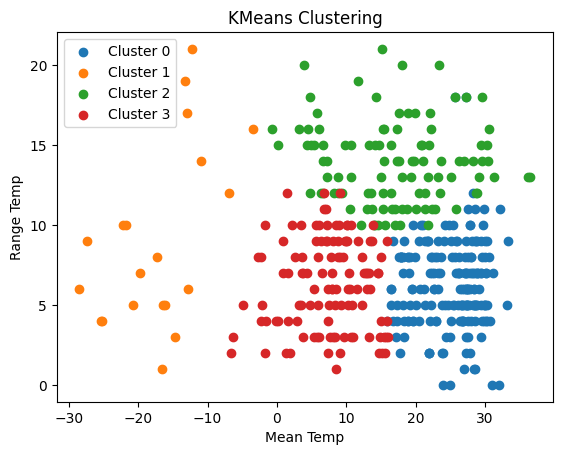

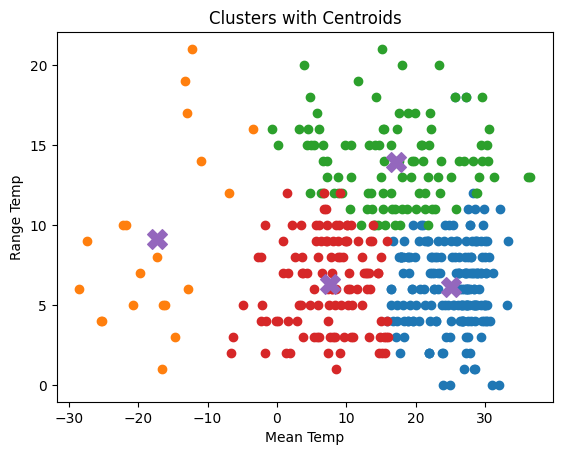

In [6]:

# ===== IMPORT =====
import numpy as np
import matplotlib.pyplot as plt

# ===== CHỌN K (sửa theo kết quả cell 1) =====
k = 4

# ===== CHẠY KMEANS =====
centroids, clusters = kmeans(X_scaled, k)

# ===== GÁN LABEL =====
labels = np.zeros(len(X_scaled))

for i, cluster in enumerate(clusters):
    for point in cluster:
        idx = np.where((X_scaled == point).all(axis=1))[0][0]
        labels[idx] = i

df['cluster'] = labels.astype(int)

# ===== IN THỐNG KÊ =====
print("=== TRUNG BÌNH MỖI CLUSTER ===")
print(df.groupby('cluster')[features].mean())

# ===== VISUAL 1 =====
plt.figure()
for i in range(k):
    data = df[df['cluster'] == i]
    plt.scatter(data['mean_temp'], data['range_temp'], label=f'Cluster {i}')

plt.xlabel("Mean Temp")
plt.ylabel("Range Temp")
plt.title("KMeans Clustering")
plt.legend()
plt.show()

# ===== VISUAL 2 (CENTROID) =====
centroids_original = scaler.inverse_transform(centroids)

plt.figure()
for i in range(k):
    data = df[df['cluster'] == i]
    plt.scatter(data['mean_temp'], data['range_temp'])

plt.scatter(centroids_original[:, 0], centroids_original[:, 4], marker='X', s=200)

plt.xlabel("Mean Temp")
plt.ylabel("Range Temp")
plt.title("Clusters with Centroids")
plt.show()

